# Saving and resuming a PDFT calculation

In [1]:
import numpy as np
from pyscf import dft, scf
from f4b import pdft, fgto
from pyscf.dft import numint
import matplotlib.pyplot as plt

# function to get density in grid given density matrix and basis functions
def D2n(D, *phis):
    ngrid = len(phis)
    n = 0.
    for phi in phis:
        n += np.einsum("pu,pv,uv->p", phi, phi, D, optimize=True)
    n /= ngrid
    return n

---
## Set up fragments and do reference calculation

A P-DFT run that stops before converging can be continued: `mf.save(path)` stores the partition potential, the fragment densities and the configuration weights, and
`restart=path` (or `Vp0=` / `dm0=` separately) starts a new calculation from them. The same state can start **any** method.

In [2]:
sep = 1.4
mol = fgto.M(atom=f"""
    H {-0.5*sep} 0 0
    H {+0.5*sep} 0 0
""", unit='bohr', basis='cc-pvdz', fragments={0: [0], 1: [1]}, ensembles={'spin': [0, 1]})

my_dft = dft.RKS(mol.mol)        # or dft.UKS for open shells
my_dft.xc = 'PBE'
my_dft.grids.level = 6           # same grid level as f4b, to compare energies cleanly
my_dft.kernel()                  # ks.e_tot, ks.make_rdm1()
Eref, Dref = my_dft.e_tot, my_dft.make_rdm1()
print(f"{Eref = :.8f}")

# Build an integration grid for the molecule.
grids = dft.gen_grid.Grids(mol.mol) # same for same basis with same number of atoms (ghost)
grids.level = 7
grids.build()
coords = grids.coords # [npoints, 3]
w = grids.weights # weights for integration
phi = dft.numint.eval_ao(mol.mol, coords, deriv=0) # AO basis functions on the grid
nref = D2n(Dref, phi)

Eref = -1.15988035


---
## First run: 15 iterations of the reference method, then save

In [3]:
mf1 = pdft.RKS(mol, method='reference', ref_dm=Dref, maxiter=15, verbose=0)
mf1.kernel()
print(f"L1 after {mf1.niter} iterations: {mf1.L1():.4f}   E - E_KS = {mf1.e_tot - Eref:+.3e}")
path = mf1.save('h2_state')          # writes h2_state.npz in the working directory
print('saved to', path)

L1 after 15 iterations: 0.1810   E - E_KS = +6.619e-03
saved to h2_state.npz


/home/ulises/Documents/Research/PDFT_package_dev/f4b/f4b/pdft.py:425: UserWarning: P-DFT did not converge in 15 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


---
## Resume from the file: 15 more iterations

The first iteration of the new run reproduces the stored result (compare the first L1 below with the one above):

In [4]:
mf2 = pdft.RKS(mol, method='reference', ref_dm=Dref, maxiter=15, verbose=0, restart=path)
mf2.kernel()
print(f"first L1 of the resumed run: {mf2.history[0]['L1']:.4f}")
print(f"L1 after 15 + {mf2.niter} iterations: {mf2.L1():.4f}   E - E_KS = {mf2.e_tot - Eref:+.3e}")

first L1 of the resumed run: 0.1810
L1 after 15 + 15 iterations: 0.1210   E - E_KS = +2.625e-03


## Start another method from a stored state

`Vp0` and `dm0` accept the file (or arrays): here the `inversion` method starts from the partition potential found by the `reference` method.
`dm0` only provides starting densities for the fragment SCF; the partition potential `Vp0` carries the progress of the run.
Stored states can be inspected with `f4b.load_state`.

In [5]:
from f4b import load_state
st = load_state(path)
print({k: np.shape(v) for k, v in st.items() if k != 'info'}, st['info'])

mf3 = pdft.RKS(mol, method='inversion', maxiter=10, verbose=0, Vp0=path, dm0=path)
mf3.kernel()
print(f"inversion from the saved Vp: E - E_KS = {mf3.e_tot - Eref:+.3e}")

{'Vp': (10, 10), 'members': (), 'frag_dm': (2, 2, 10, 10), 'omega': (0,)} {'e_tot': -1.1532615597134597, 'e_f': -0.9791402541432868, 'Ep': -0.1741213055701729, 'niter': 15, 'converged': False, 'method': 'reference'}


inversion from the saved Vp: E - E_KS = +6.818e-04


/home/ulises/Documents/Research/PDFT_package_dev/f4b/f4b/pdft.py:425: UserWarning: P-DFT did not converge in 10 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


---
## Plot: L1 error of the two runs

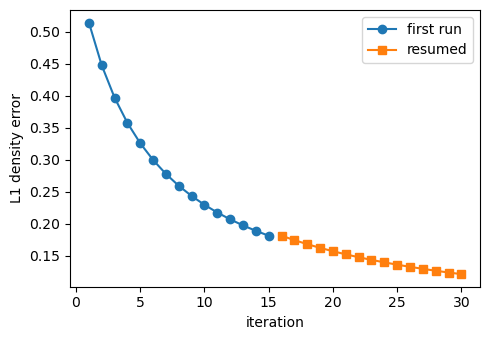

In [6]:
fig, ax = plt.subplots(figsize=(5, 3.5))
L1a = [h['L1'] for h in mf1.history]; L1b = [h['L1'] for h in mf2.history]
ax.plot(range(1, len(L1a) + 1), L1a, 'o-', label='first run')
ax.plot(range(len(L1a) + 1, len(L1a) + len(L1b) + 1), L1b, 's-', label='resumed')
ax.set_xlabel('iteration'); ax.set_ylabel('L1 density error'); ax.legend()
fig.tight_layout(); plt.show()
import os; os.remove(path)          # remove the example file